# Predictia performantei ofensive a jucatorilor

Notebookul exploreaza datele FBref la nivel de jucator-meci si compara regresia logistica cu padurea aleatoare. Tinta este daca jucatorul inscrie cel putin un gol sau ofera cel putin un assist in meciul curent.

Pentru predictie se folosesc doar date din aparitiile anterioare ale jucatorului. Minutele, golurile, assisturile, suturile si cartonasele sunt rezumate pe toate aparitiile anterioare disponibile; golurile si assisturile din meciul curent definesc tinta.

## 1. Date de intrare

Ruleaza mai intai `extraction/data_scraper.ipynb`. Modelul citeste `data/raw/fbref/fbref_player_match_stats.csv`, cu un singur furnizor de date, FBref. Graficele si rezultatele folosesc competitiile prezente efectiv in CSV.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

CWD = Path.cwd().resolve()
if CWD.name == "notebooks" and (CWD.parent / "README.md").exists():
    PROJECT_ROOT = CWD.parent
elif (CWD / "notebooks").is_dir() and (CWD / "README.md").exists():
    PROJECT_ROOT = CWD
else:
    candidates = [p for p in (CWD, *CWD.parents) if (p / "notebooks").is_dir() and (p / "README.md").exists()]
    if not candidates:
        raise RuntimeError("Deschide Jupyter din IAPD_project/ sau din directorul notebooks/.")
    PROJECT_ROOT = candidates[0]

DATA_ROOT = PROJECT_ROOT / "data"
MODEL_SOURCES = ["fbref"]  # Foloseste exportul FBref cu toate competitiile.
INPUT_FILES = {
    "fbref": DATA_ROOT / "raw" / "fbref" / "fbref_player_match_stats.csv",
}
if not MODEL_SOURCES or any(source not in INPUT_FILES for source in MODEL_SOURCES):
    raise ValueError(f"Surse invalide: {MODEL_SOURCES}")
OUTPUT_DIR = DATA_ROOT / "processed"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Asociaza fiecare camp cu numele coloanei din setul de date ales.
# Exportul FBref contine aceste campuri comune pentru competitiile selectate.
COLUMN_MAP = {
    "player": "player",
    "match_date": "date",
    "minutes": "Min",
    "goals": "Gls",
    "assists": "Ast",
    "shots": "Sh",
    "yellow_cards": "CrdY",
    "red_cards": "CrdR",
    # Optional: "match_id": "game_id",
}

In [2]:
frames = []
for source in MODEL_SOURCES:
    input_file = INPUT_FILES[source]
    if not input_file.exists():
        raise FileNotFoundError(
            f"Fisierul {input_file} lipseste. Ruleaza mai intai extraction/data_scraper.ipynb."
        )
    source_frame = pd.read_csv(input_file)
    source_frame["source"] = source
    frames.append(source_frame)

raw = pd.concat(frames, ignore_index=True, sort=False)
MIN_DATA_ROWS = 1_000
if len(raw) < MIN_DATA_ROWS:
    raise ValueError(f"Criteriul setului de date nu este indeplinit: {len(raw):,} randuri; sunt necesare cel putin {MIN_DATA_ROWS:,}.")
print(f"Incarcate {len(raw):,} randuri din sursele {', '.join(MODEL_SOURCES)}")
print("Randuri pe sursa:")
display(raw.groupby("source").size().rename("randuri").to_frame())
raw.head()


Incarcate 66,731 randuri din sursele fbref
Randuri pe sursa:


,randuri
source,
fbref,66731


,league,season,game,team,player,jersey_number,nation,pos,age,Min,...,Off,Crs,TklW,Int,OG,PKwon,PKcon,game_id,date,source
0,Champions League,2324,2023-09-19 Barcelona es-be Antwerp,Antwerp,Alhassan Yusuf,8,NGA,MF,23-063,30.0,...,0.0,1.0,1.0,0.0,0.0,NaN,NaN,c9d2ec0f,2023-09-19 00:00:00+00:00,fbref
1,Champions League,2324,2023-09-19 Barcelona es-be Antwerp,Antwerp,Anthony Valencia,55,ECU,MF,20-060,8.0,...,0.0,1.0,0.0,0.0,0.0,NaN,NaN,c9d2ec0f,2023-09-19 00:00:00+00:00,fbref
2,Champions League,2324,2023-09-19 Barcelona es-be Antwerp,Antwerp,Arbnor Muja,11,ALB,AM,24-294,82.0,...,0.0,1.0,0.0,0.0,0.0,NaN,NaN,c9d2ec0f,2023-09-19 00:00:00+00:00,fbref
3,Champions League,2324,2023-09-19 Barcelona es-be Antwerp,Antwerp,Arthur Vermeeren,48,BEL,DM,18-224,90.0,...,0.0,0.0,2.0,2.0,0.0,NaN,NaN,c9d2ec0f,2023-09-19 00:00:00+00:00,fbref
4,Champions League,2324,2023-09-19 Barcelona es-be Antwerp,Antwerp,George Ilenikhena,9,NGA,FW,17-034,31.0,...,0.0,0.0,0.0,0.0,0.0,NaN,NaN,c9d2ec0f,2023-09-19 00:00:00+00:00,fbref


## 2. Standardizarea coloanelor

Coloanele FBref folosite in model sunt redenumite in nume comune, precum `minutes`, `goals` si `assists`. Coloana `source` pastreaza furnizorul (`fbref`), iar `league` identifica competitia. Caracteristicile istorice se calculeaza pentru fiecare jucator pe aparitiile anterioare, indiferent de competitie.

In [3]:
required = ["player", "match_date", "minutes", "goals", "assists", "shots", "yellow_cards", "red_cards"]
missing_mapping = [key for key in required if COLUMN_MAP.get(key) not in raw.columns]
if missing_mapping:
    raise KeyError(
        "Nu au fost gasite coloanele mapate: " + ", ".join(f"{key} -> {COLUMN_MAP.get(key)!r}" for key in missing_mapping)
        + ". Actualizeaza COLUMN_MAP cu antetele exacte de mai sus."
    )

rename = {source: canonical for canonical, source in COLUMN_MAP.items() if source in raw.columns}
data = raw.rename(columns=rename).copy()
if "match_id" in COLUMN_MAP and COLUMN_MAP["match_id"] in raw.columns:
    data = data.rename(columns={COLUMN_MAP["match_id"]: "match_id"})

data["match_date"] = pd.to_datetime(data["match_date"], format="mixed", errors="coerce", utc=True)
numeric = ["minutes", "goals", "assists", "shots", "yellow_cards", "red_cards"]
for col in numeric:
    data[col] = pd.to_numeric(data[col], errors="coerce")
data["player"] = data["player"].astype("string").str.strip()
data = data.dropna(subset=["player", "match_date"]).copy()
data = data[data["minutes"].fillna(0) > 0].copy()
data = data.sort_values(["player", "match_date"]).reset_index(drop=True)

print(f"Randuri jucator-meci utilizabile: {len(data):,}")
print("Valori lipsa pe camp:")
display(data[required].isna().sum().to_frame("missing_rows"))

Randuri jucator-meci utilizabile: 66,729
Valori lipsa pe camp:


,missing_rows
player,0
match_date,0
minutes,0
goals,0
assists,0
shots,0
yellow_cards,0
red_cards,0


## 3. Explorarea vizuala a datelor

Graficele arata cate observatii exista in fiecare competitie, cat de des apare o contributie la gol si cum se distribuie golurile si suturile. O observatie reprezinta un rand jucator-meci; jucatorii cu mai multe aparitii contribuie cu mai multe randuri. Aceste statistici descriu meciurile jucate si nu sunt folosite ca predictori pentru meciul curent.

,randuri jucator-meci,% cu gol sau assist
league,,
ITA-Serie A,11910,12.3
ESP-La Liga,11888,12.1
ENG-Premier League,11384,15.3
GER-Bundesliga,9590,14.7
FRA-Ligue 1,9457,12.4
Europa League,4376,14.1
Conference League,4324,13.8
Champions League,3800,14.2


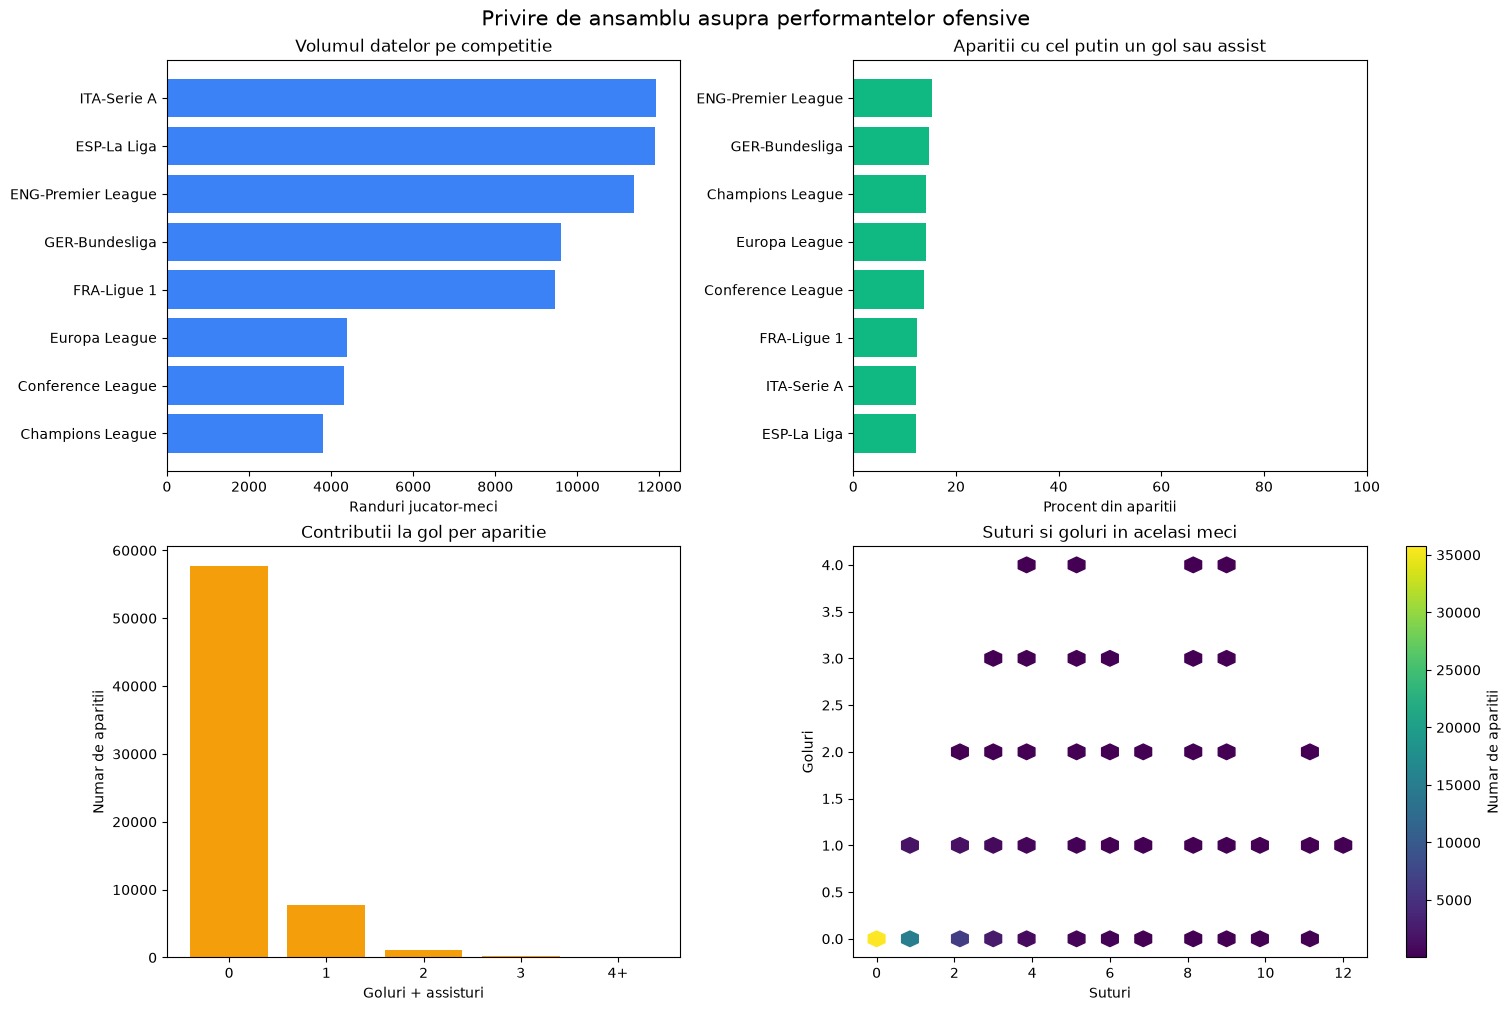

In [4]:
# Pregateste sumarul pentru grafice. O contributie inseamna gol sau assist.
data["goal_contributions"] = data[["goals", "assists"]].sum(axis=1, min_count=2)
data["has_goal_contribution"] = (data["goal_contributions"] >= 1).where(data["goal_contributions"].notna(), np.nan)
league_summary = (
    data.groupby("league", dropna=False)
    .agg(aparitii=("player", "size"), rata_contributiilor=("has_goal_contribution", "mean"))
    .sort_values("aparitii", ascending=False)
)
league_summary["rata_contributiilor"] = league_summary["rata_contributiilor"] * 100
display(league_summary.rename(columns={"aparitii": "randuri jucator-meci", "rata_contributiilor": "% cu gol sau assist"}).round(1))

fig, axes = plt.subplots(2, 2, figsize=(15, 10), constrained_layout=True)

# Numarul de aparitii pentru fiecare competitie.
plot_counts = league_summary["aparitii"].sort_values()
axes[0, 0].barh(plot_counts.index.astype(str), plot_counts.values, color="#3b82f6")
axes[0, 0].set_title("Volumul datelor pe competitie")
axes[0, 0].set_xlabel("Randuri jucator-meci")
axes[0, 0].set_ylabel("")

# Rata este calculata pe randuri jucator-meci, nu pe jucatori unici.
plot_rates = league_summary["rata_contributiilor"].sort_values()
axes[0, 1].barh(plot_rates.index.astype(str), plot_rates.values, color="#10b981")
axes[0, 1].set_title("Aparitii cu cel putin un gol sau assist")
axes[0, 1].set_xlabel("Procent din aparitii")
axes[0, 1].set_ylabel("")
axes[0, 1].set_xlim(0, max(100, float(plot_rates.max()) * 1.12))

# Gruparea 4+ pastreaza vizibilitatea valorilor rare.
contribution_counts = data["goal_contributions"].clip(upper=4).value_counts().reindex([0, 1, 2, 3, 4], fill_value=0)
axes[1, 0].bar(["0", "1", "2", "3", "4+"], contribution_counts.values, color="#f59e0b")
axes[1, 0].set_title("Contributii la gol per aparitie")
axes[1, 0].set_xlabel("Goluri + assisturi")
axes[1, 0].set_ylabel("Numar de aparitii")

# Hexbin reduce suprapunerea punctelor atunci cand sunt multe observatii.
shot_goal_data = data[["shots", "goals"]].apply(pd.to_numeric, errors="coerce").dropna()
if not shot_goal_data.empty:
    hb = axes[1, 1].hexbin(shot_goal_data["shots"], shot_goal_data["goals"], gridsize=28, mincnt=1, cmap="viridis")
    fig.colorbar(hb, ax=axes[1, 1], label="Numar de aparitii")
axes[1, 1].set_title("Suturi si goluri in acelasi meci")
axes[1, 1].set_xlabel("Suturi")
axes[1, 1].set_ylabel("Goluri")
fig.suptitle("Privire de ansamblu asupra performantelor ofensive", fontsize=15)
plt.show()

### Corelatii intre statisticile din acelasi meci

Matricea foloseste statisticile numerice disponibile in export. Valorile apropiate de 1 indica o asociere pozitiva, cele apropiate de -1 o asociere negativa, iar cele din jurul lui 0 o relatie liniara slaba. Corelatia nu arata cauza si efectul. Statisticile meciului curent apar aici doar pentru explorare; modelul foloseste caracteristici derivate din aparitiile anterioare.

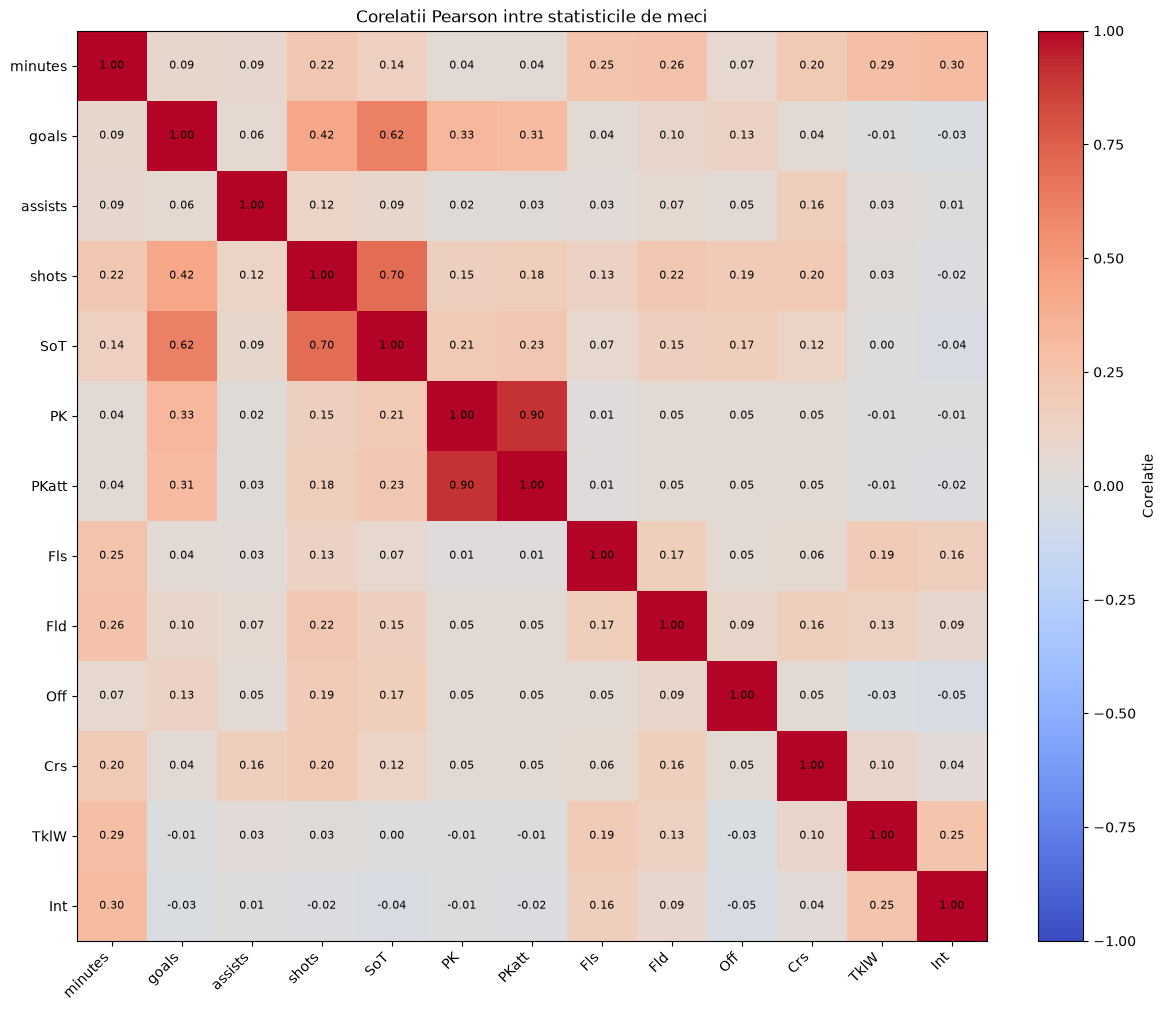

,minutes,goals,assists,shots,SoT,PK,PKatt,Fls,Fld,Off,Crs,TklW,Int
minutes,1.00,0.09,0.09,0.22,0.14,0.04,0.04,0.25,0.26,0.07,0.20,0.29,0.30
goals,0.09,1.00,0.06,0.42,0.62,0.33,0.31,0.04,0.10,0.13,0.04,-0.01,-0.03
assists,0.09,0.06,1.00,0.12,0.09,0.02,0.03,0.03,0.07,0.05,0.16,0.03,0.01
shots,0.22,0.42,0.12,1.00,0.70,0.15,0.18,0.13,0.22,0.19,0.20,0.03,-0.02
SoT,0.14,0.62,0.09,0.70,1.00,0.21,0.23,0.07,0.15,0.17,0.12,0.00,-0.04
PK,0.04,0.33,0.02,0.15,0.21,1.00,0.90,0.01,0.05,0.05,0.05,-0.01,-0.01
PKatt,0.04,0.31,0.03,0.18,0.23,0.90,1.00,0.01,0.05,0.05,0.05,-0.01,-0.02
Fls,0.25,0.04,0.03,0.13,0.07,0.01,0.01,1.00,0.17,0.05,0.06,0.19,0.16
Fld,0.26,0.10,0.07,0.22,0.15,0.05,0.05,0.17,1.00,0.09,0.16,0.13,0.09
Off,0.07,0.13,0.05,0.19,0.17,0.05,0.05,0.05,0.09,1.00,0.05,-0.03,-0.05


In [5]:
correlation_candidates = [
    "minutes", "goals", "assists", "shots", "SoT", "PK", "PKatt",
    "CrdY", "CrdR", "Fls", "Fld", "Off", "Crs", "TklW", "Int",
]
available_stats = [column for column in correlation_candidates if column in data.columns]
correlation_data = data[available_stats].apply(pd.to_numeric, errors="coerce")
correlation_data = correlation_data.dropna(axis=1, how="all")
correlation_data = correlation_data.loc[:, correlation_data.nunique(dropna=True) > 1]

if correlation_data.shape[1] < 2:
    print("Nu sunt suficiente statistici numerice pentru matricea de corelatii.")
else:
    correlation_matrix = correlation_data.corr()
    fig, ax = plt.subplots(figsize=(12, 10), constrained_layout=True)
    image = ax.imshow(correlation_matrix, cmap="coolwarm", vmin=-1, vmax=1)
    ax.set_xticks(range(len(correlation_matrix.columns)))
    ax.set_yticks(range(len(correlation_matrix.index)))
    ax.set_xticklabels(correlation_matrix.columns, rotation=45, ha="right")
    ax.set_yticklabels(correlation_matrix.index)
    ax.set_title("Corelatii Pearson intre statisticile de meci")
    for row in range(len(correlation_matrix.index)):
        for column in range(len(correlation_matrix.columns)):
            value = correlation_matrix.iloc[row, column]
            if pd.notna(value):
                ax.text(column, row, f"{value:.2f}", ha="center", va="center", fontsize=8)
    fig.colorbar(image, ax=ax, label="Corelatie")
    plt.show()
    display(correlation_matrix.round(2))

## 4. Definirea tintei si crearea caracteristicilor pre-meci

Tinta este 1 daca jucatorul are cel putin un gol sau assist in meciul curent si 0 in caz contrar. Minutele, golurile, assisturile, suturile si cartonasele sunt rezumate prin medie si suma pe toate aparitiile anterioare disponibile din dataset. Competitia meciului curent este inclusa ca variabila categorica.

In [6]:
data = data.dropna(subset=["goals", "assists"]).copy()
data["goal_contributions"] = data["goals"] + data["assists"]
data["high_offensive_performance"] = (data["goal_contributions"] >= 1).astype(int)

past_fields = ["minutes", "goals", "assists", "shots", "yellow_cards", "red_cards"]
for field in past_fields:
    data[f"all_previous_mean_{field}"] = (
        data.groupby("player", sort=False)[field]
        .transform(lambda series: series.shift(1).expanding(min_periods=1).mean())
    )
    data[f"all_previous_sum_{field}"] = (
        data.groupby("player", sort=False)[field]
        .transform(lambda series: series.shift(1).expanding(min_periods=1).sum())
    )

competition_features = pd.get_dummies(data["league"].fillna("unknown"), prefix="competition", dtype=int)
data = pd.concat([data, competition_features], axis=1)
feature_cols = [col for col in data.columns if col.startswith("all_previous_")] + list(competition_features.columns)
model_data = data.dropna(subset=feature_cols + ["high_offensive_performance"]).copy()
print("Distributia tintei (0 = fara contributie la gol, 1 = cel putin una):")
display(model_data["high_offensive_performance"].value_counts(normalize=True).rename("share").to_frame())
if len(model_data) < MIN_DATA_ROWS:
    raise ValueError(
        f"Criteriul pentru setul de modelare nu este indeplinit: {len(model_data):,} randuri jucator-meci utilizabile; "
        f"sunt necesare cel putin {MIN_DATA_ROWS:,}."
    )
if len(feature_cols) < 10:
    raise ValueError(f"Criteriul caracteristicilor modelului nu este indeplinit: {len(feature_cols)} engineered features; sunt necesare cel putin 10.")
print(f"OK — setul de modelare are {len(model_data):,} randuri utilizabile si {len(feature_cols):,} caracteristici pre-meci")

Distributia tintei (0 = fara contributie la gol, 1 = cel putin una):


,share
high_offensive_performance,
0,0.863714
1,0.136286


OK — setul de modelare are 62,611 randuri utilizabile si 20 caracteristici pre-meci


## 5. Impartirea cronologica antrenare/test

Datele FBref sunt impartite dupa timp: cele mai recente 20% dintre datele distincte sunt pastrate pentru test, separat pe sursa. In configuratia curenta exista o singura sursa, FBref. Datele din aceeasi zi raman in acelasi set.

In [7]:
train_parts = []
test_parts = []
for source, source_data in model_data.groupby("source", sort=False):
    source_dates = source_data["match_date"].drop_duplicates().sort_values().reset_index(drop=True)
    split_index = int(len(source_dates) * 0.8)
    if split_index <= 0 or split_index >= len(source_dates):
        raise ValueError(f"Nu sunt suficiente date distincte pentru impartirea cronologica a sursei {source}.")
    split_date = source_dates.iloc[split_index]
    train_parts.append(source_data[source_data["match_date"] < split_date].copy())
    test_parts.append(source_data[source_data["match_date"] >= split_date].copy())

train = pd.concat(train_parts, ignore_index=True)
test = pd.concat(test_parts, ignore_index=True)
X_train, X_test = train[feature_cols], test[feature_cols]
y_train = train["high_offensive_performance"]
y_test = test["high_offensive_performance"]
if y_train.nunique() < 2 or y_test.nunique() < 2:
    raise ValueError("Impartirea cronologica nu contine ambele clase in antrenare si test.")
print(f"Randuri de antrenare: {len(train):,}")
print(f"Randuri de test: {len(test):,}")
print("Randuri de test pe sursa:")
display(test.groupby("source").size().rename("randuri").to_frame())


Randuri de antrenare: 53,053
Randuri de test: 9,558
Randuri de test pe sursa:


,randuri
source,
fbref,9558


## 6. Antrenarea si compararea modelelor

Sunt comparate doua modele de baza: regresia logistica si padurea aleatoare. Valorile lipsa din caracteristici sunt completate cu mediana; regresia logistica scaleaza si caracteristicile. Comparatia include acuratete, precizie, recall, F1, ROC AUC si media preciziei (PR AUC).

In [8]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

models = {
    "Regresie logistica": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(class_weight="balanced", max_iter=2000, random_state=42)),
    ]),
    "Padure aleatoare": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=400, min_samples_leaf=3, class_weight="balanced",
            random_state=42, n_jobs=-1,
        )),
    ]),
}

results = []
predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    predicted = model.predict(X_test)
    probability = model.predict_proba(X_test)[:, 1]
    predictions[name] = (predicted, probability)
    results.append({
        "model": name,
        "accuracy": accuracy_score(y_test, predicted),
        "precision": precision_score(y_test, predicted, zero_division=0),
        "recall": recall_score(y_test, predicted, zero_division=0),
        "f1": f1_score(y_test, predicted, zero_division=0),
        "roc_auc": roc_auc_score(y_test, probability),
        "average_precision": average_precision_score(y_test, probability),
    })

comparison = pd.DataFrame(results).set_index("model").sort_values("average_precision", ascending=False)
display(comparison.round(3))

,accuracy,precision,recall,f1,roc_auc,average_precision
model,,,,,,
Regresie logistica,0.687,0.249,0.614,0.354,0.716,0.293
Padure aleatoare,0.774,0.287,0.420,0.341,0.699,0.281


## 7. Evaluarea modelelor si salvarea rezultatelor

Modelul cu cea mai buna medie a preciziei pe setul de test este afisat impreuna cu matricea de confuzie. Metricile sunt calculate si separat pentru fiecare competitie. Fisierele rezultate sunt salvate in `data/processed/` din radacina proiectului.

In [ ]:
best_name = comparison.index[0]
best_model = models[best_name]
best_pred, best_probability = predictions[best_name]
print("Selectat dupa media preciziei:", best_name)
print("Matrice de confuzie (randuri = real [0, 1], coloane = prezis [0, 1]):")
print(confusion_matrix(y_test, best_pred))

comparison.to_csv(OUTPUT_DIR / "model_comparison.csv", encoding="utf-8-sig")
test_results = test[["source", "player", "match_date", "goals", "assists", "high_offensive_performance"]].copy()
test_results["predicted_high_performance"] = best_pred
test_results["predicted_probability"] = best_probability
test_results.to_csv(OUTPUT_DIR / "test_predictions.csv", index=False, encoding="utf-8-sig")
competition_scores = []
test_predictions = pd.Series(best_pred, index=test.index)
test_probabilities = pd.Series(best_probability, index=test.index)
for competition in test["league"].dropna().unique():
    positions = test.index[test["league"].eq(competition)]
    source_actual = y_test.loc[positions]
    source_pred = test_predictions.loc[positions]
    source_prob = test_probabilities.loc[positions]
    competition_scores.append({
        "competition": competition,
        "rows": len(positions),
        "precision": precision_score(source_actual, source_pred, zero_division=0),
        "recall": recall_score(source_actual, source_pred, zero_division=0),
        "f1": f1_score(source_actual, source_pred, zero_division=0),
        "average_precision": average_precision_score(source_actual, source_prob),
    })
competition_comparison = pd.DataFrame(competition_scores).set_index("competition")
display(competition_comparison.round(3))
competition_comparison.to_csv(OUTPUT_DIR / "competition_metrics.csv", encoding="utf-8-sig")
print("Salvat:", OUTPUT_DIR / "model_comparison.csv")
print("Salvat:", OUTPUT_DIR / "test_predictions.csv")
print("Salvat:", OUTPUT_DIR / "competition_metrics.csv")

## Interpretare si limitari

- Tinta „cel putin un gol sau assist” este o masura simpla si nu acopera toate aspectele performantei ofensive.
- Modelul foloseste forma recenta si competitia; nu include adversarul, accidentarile sau minutele estimate inaintea meciului.
- Graficele si matricea de corelatii descriu datele observate; corelatia nu demonstreaza cauzalitate.
- Evaluarea imparte cronologic meciurile din sezonul 2023/24. Pentru o estimare reala pe sezonul urmator este necesara o evaluare pe date din acel sezon.